# CA3

**Group:** 12

**Members:** Kiki Julia, Sathusan and Durga


Classification of wine: predict whether a wine is good (1) or bad (0) from 11 physicochemical measurements.

### Imports

In [82]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [83]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.inspection import DecisionBoundaryDisplay

### Reading data

The code in this section has been reused from previous assignments

In [84]:
sample_sub = pd.read_csv("/content/drive/MyDrive/DAT200_CA_H26/sample_submission.csv", sep=',')

sample_sub.head()

,ID,quality
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


In [85]:
train = pd.read_csv("/content/drive/MyDrive/DAT200_CA_H26/train.csv", sep=',')

train.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.8,0.610,0.29,1.6,0.114,9.0,29.0,0.99740,3.26,1.56,9.1,0,13
1,8.4,1.035,0.15,6.0,0.073,11.0,54.0,0.99900,3.37,0.49,9.9,0,705
2,8.1,0.290,0.36,2.2,0.048,35.0,53.0,0.99500,3.27,1.01,12.4,1,1408
3,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,1,144
4,15.6,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,0,557


In [86]:
test = pd.read_csv("/content/drive/MyDrive/DAT200_CA_H26/test.csv", sep=',')

test.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Id
0,7.0,0.69,0.07,2.5,0.091,15.0,21.0,0.99572,3.38,0.60,11.3,1117
1,6.4,0.47,0.40,2.4,0.071,8.0,19.0,0.99630,3.56,0.73,10.6,1411
2,7.9,0.53,0.24,2.0,0.072,15.0,105.0,0.99600,3.27,0.54,9.4,311
3,7.6,0.41,0.24,1.8,0.080,4.0,11.0,0.99620,3.28,0.59,9.5,26
4,8.1,0.87,0.00,2.2,0.084,10.0,31.0,0.99656,3.25,0.50,9.8,757


### Data exploration and visualisation

In [87]:
train.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000
mean,8.310898,0.540042,0.260790,2.542994,0.088674,15.859880,47.077246,0.996799,3.308707,0.658048,10.396287,0.500599,800.470659
std,1.757359,0.179786,0.197739,1.420451,0.051485,10.444733,33.271056,0.001946,0.159072,0.179891,1.087407,0.500299,468.873363
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,7.000000,0.990070,2.740000,0.330000,8.400000,0.000000,0.000000
25%,7.100000,0.410000,0.080000,1.900000,0.071000,7.000000,22.000000,0.995600,3.200000,0.550000,9.500000,0.000000,408.000000
50%,7.900000,0.540000,0.240000,2.200000,0.080000,13.000000,38.000000,0.996750,3.310000,0.610000,10.100000,1.000000,784.000000
75%,9.100000,0.647500,0.410000,2.600000,0.091000,21.000000,63.000000,0.997900,3.400000,0.725000,11.000000,1.000000,1225.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,1.000000,1597.000000


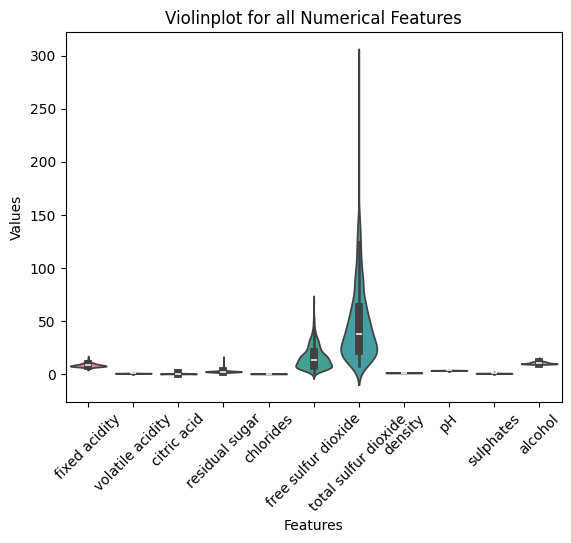

In [88]:
# Plot violinplot of all features
sns.violinplot(data=train.drop(columns=["Id", "quality"]))

plt.title("Violinplot for all Numerical Features")
plt.ylabel("Values")
plt.xlabel("Features")
plt.xticks(rotation=45)
plt.show()

On the raw scale, free and total sulfur dioxide dominate because they are measured in much larger units. The features must therefore be standardised before using distance-based models (kNN, SVM).

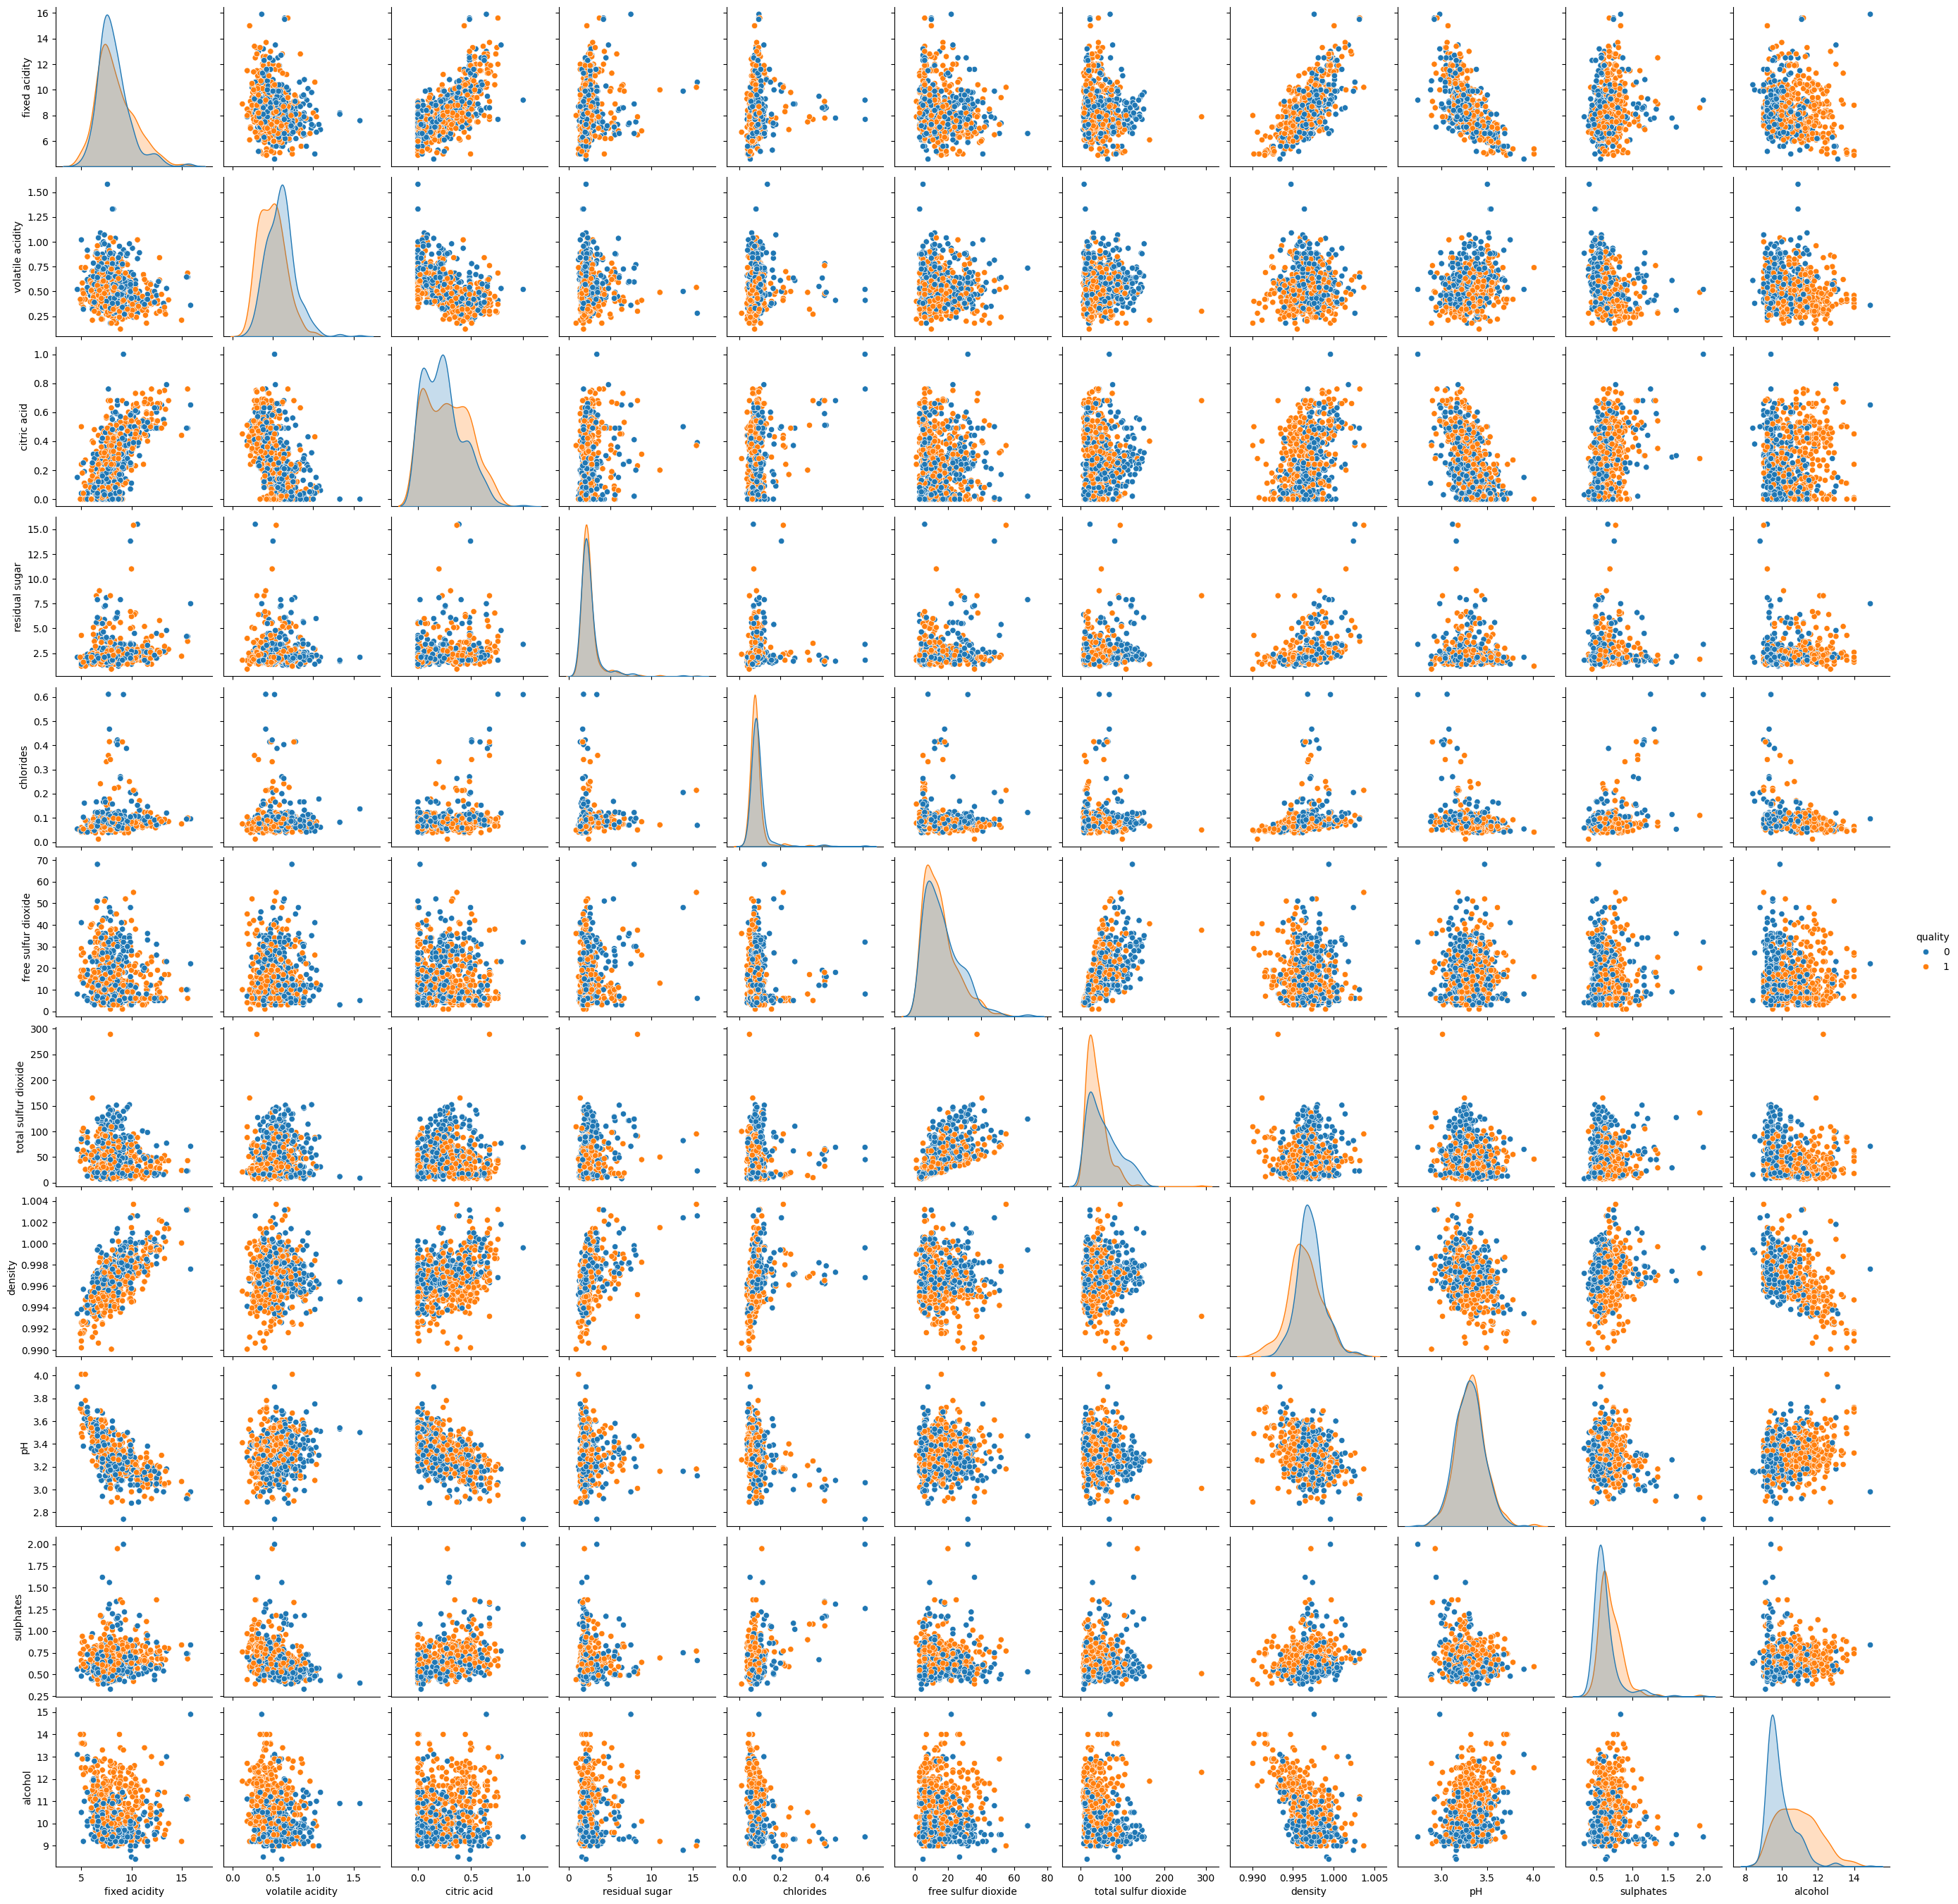

In [89]:
# Plot the pairplot for all variables
sns.pairplot(train.drop(columns="Id"), hue="quality")

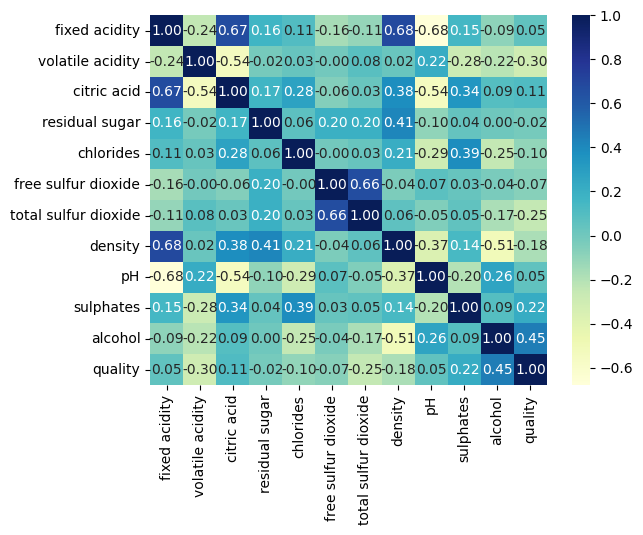

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.000000,-0.239654,0.670481,0.164619,0.107532,-0.162457,-0.110240,0.683265,-0.678121,0.151310,-0.094171,0.051339
volatile acidity,-0.239654,1.000000,-0.535085,-0.019741,0.034499,-0.004585,0.079104,0.023651,0.216863,-0.283993,-0.217002,-0.302238
citric acid,0.670481,-0.535085,1.000000,0.166999,0.277673,-0.061630,0.027693,0.381371,-0.542874,0.338861,0.092857,0.111017
residual sugar,0.164619,-0.019741,0.166999,1.000000,0.063488,0.199822,0.196233,0.410604,-0.098347,0.038467,0.004347,-0.020452
chlorides,0.107532,0.034499,0.277673,0.063488,1.000000,-0.003597,0.034344,0.211559,-0.292120,0.385702,-0.247526,-0.103287
free sulfur dioxide,-0.162457,-0.004585,-0.061630,0.199822,-0.003597,1.000000,0.659305,-0.037447,0.074736,0.032304,-0.035300,-0.074444
total sulfur dioxide,-0.110240,0.079104,0.027693,0.196233,0.034344,0.659305,1.000000,0.061933,-0.054809,0.051520,-0.174027,-0.250267
density,0.683265,0.023651,0.381371,0.410604,0.211559,-0.037447,0.061933,1.000000,-0.367657,0.136117,-0.508704,-0.179263
pH,-0.678121,0.216863,-0.542874,-0.098347,-0.292120,0.074736,-0.054809,-0.367657,1.000000,-0.202909,0.261024,0.049578
sulphates,0.151310,-0.283993,0.338861,0.038467,0.385702,0.032304,0.051520,0.136117,-0.202909,1.000000,0.093781,0.219372


In [90]:
# Compute correlation matrix
co_mtx = train.drop(columns="Id").corr()

# Plot correlation heatmap
sns.heatmap(co_mtx, cmap="YlGnBu", annot=True, fmt=".2f")

# Display heatmap
plt.show()

# Show correlation matrix
co_mtx

The following variables are moderately correlated:
* "fixed acidity" and "density" : 0.683265
* "fixed acidity" and "citric acid" : 0.670481
* "fixed acidity" and "pH" : -0.678121
* "total sulfur dioxide" and "free sulfur dioxide" : 0.659305


**Conclusions from data exploration**
- The classes are balanced (mean of quality = 0.50), so accuracy is a suitable metric.
- Strongest correlation with quality: alcohol (+0.45), volatile acidity (−0.30), total sulfur dioxide (−0.25), sulphates (+0.22). All other features have |r| < 0.2.
- residual sugar, chlorides, total sulfur dioxide and sulphates have extreme values (7–10 sd from the mean), i.e. possible outliers.
- The pairplot shows that the two classes overlap strongly, so no single feature separates them. This suggests non-linear models.

### Data cleaning

Checking for duplicate rows

In [91]:
print("Duplicates  train:", train.duplicated().sum(), " test:", test.duplicated().sum())

Duplicates  train: 0  test: 0


Handling missing values

In [92]:
print("Missing values  train:", train.isna().sum().sum(), " test:", test.isna().sum().sum())

Missing values  train: 0  test: 0


Handling outliers

In [93]:
test.dtypes

,0
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


All features are numeric and there are no missing values or duplicates. Outliers are removed for all features at once: a row is dropped if any feature is more than 4 standard deviations from its mean. This is only done on the training data, since every test row needs a prediction.

In [94]:
# Remove outliers from training data: any feature more than 4 sd from the mean
features = train.drop(columns=["quality", "Id"]).columns
z = (train[features] - train[features].mean()) / train[features].std()
outlier = (z.abs() > 4).any(axis=1)
print("Rows removed:", outlier.sum(), "of", len(train))
train = train[~outlier].reset_index(drop=True)

Rows removed: 37 of 835


### Data preprocessing and visualisation

Feature standardizing

In [95]:
# Initialise standard scaler and compute mean and sd from training data
features = train.drop(columns=["quality", "Id"]).columns

sc = StandardScaler().set_output(transform="pandas")
sc.fit(train[features])

# Transform (standardise) both X_train and X_test with mean and sd from training data
train_sc = sc.transform(train[features])
test_sc = sc.transform(test[features])

test_sc.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,-0.753470,0.880947,-0.962571,0.073044,0.324096,-0.061757,-0.791884,-0.546760,0.440710,-0.307680,0.831309
1,-1.106811,-0.391077,0.764156,-0.031230,-0.461651,-0.763635,-0.854579,-0.234846,1.652959,0.592708,0.178739
2,-0.223458,-0.044161,-0.073045,-0.448323,-0.422364,-0.061757,1.841326,-0.396181,-0.300108,-0.723244,-0.939954
3,-0.400128,-0.737993,-0.073045,-0.656869,-0.108065,-1.164708,-1.105361,-0.288624,-0.232761,-0.376941,-0.846730
4,-0.105678,1.921694,-1.328847,-0.239776,0.049085,-0.563098,-0.478406,-0.095022,-0.434803,-1.000286,-0.567057


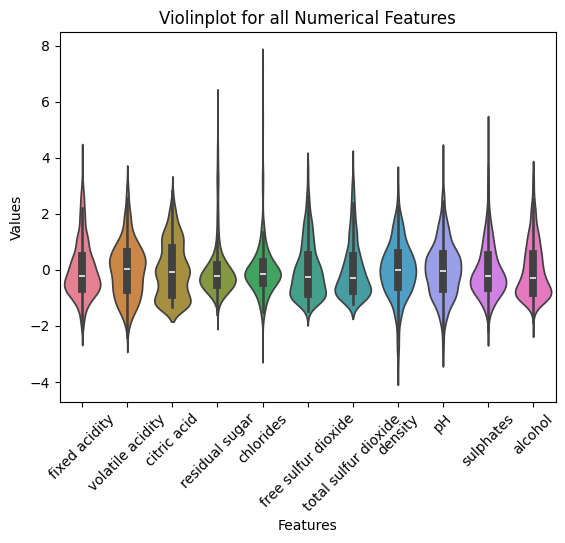

In [96]:
# Plot violinplot of all features after standardizing
sns.violinplot(data=train_sc)

plt.title("Violinplot for all Numerical Features")
plt.ylabel("Values")
plt.xlabel("Features")
plt.xticks(rotation=45)
plt.show()

Feature selection

No feature has a strong correlation with quality on its own (max 0.45 for alcohol). We therefore first use all 11 features, and also try the four features with |r| > 0.2.


### Modelling

Use the practice of using many train_test_splits (of the training data) while searching for the best (hyper-)parameters of each classifier

In [97]:
X = train_sc
y = train["quality"]

In [98]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

#### Decision Tree

Accuracy on train data: 0.75
Accuracy on validation data: 0.73
Features used for plot: ['alcohol', 'sulphates']


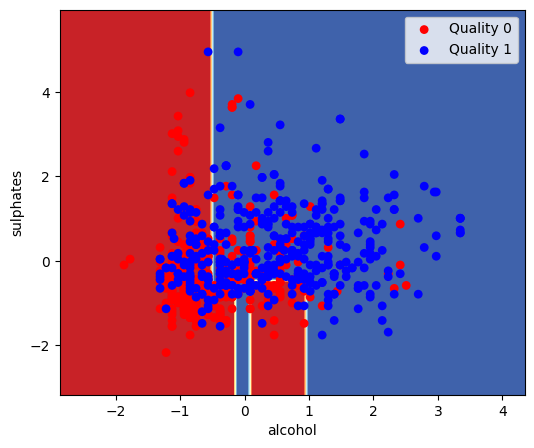

In [99]:
clf = DecisionTreeClassifier(max_depth=3, criterion='gini', min_samples_leaf=1, random_state=42)
clf.fit(X_train, y_train)

print(f'Accuracy on train data: {accuracy_score(y_train, clf.predict(X_train)):.2f}')
print(f'Accuracy on validation data: {accuracy_score(y_test, clf.predict(X_test)):.2f}')

# --- Pick the 2 most important features for plotting ---
importances = pd.Series(clf.feature_importances_, index=X.columns)
top2 = importances.nlargest(2).index.tolist()
print('Features used for plot:', top2)

X_2d = X[top2].values
y_arr = np.asarray(y)

# --- Separate 2-feature model, only for visualization ---
clf_2d = DecisionTreeClassifier(max_depth=3, criterion='gini', min_samples_leaf=1, random_state=42)
clf_2d.fit(X_2d, y_arr)

# --- Plot decision boundary ---
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
DecisionBoundaryDisplay.from_estimator(
    clf_2d,
    X_2d,
    cmap=plt.cm.RdYlBu,
    response_method="predict",
    ax=ax,
    xlabel=top2[0],
    ylabel=top2[1],
)

class_names = {0: 'Quality 0', 1: 'Quality 1'}
plot_colors = ["red", "blue"]
for cls, color in zip(np.unique(y_arr), plot_colors):
    idx = np.where(y_arr == cls)
    ax.scatter(
        X_2d[idx, 0],
        X_2d[idx, 1],
        c=color,
        label=class_names[cls],
        edgecolor="none",
        s=40,
    )

ax.legend()
plt.show()

The tree mainly uses alcohol and sulphates. Train and validation accuracy are close (0.76 vs 0.74), so depth 3 does not overfit, but many points lie on the wrong side of the boundary because the classes overlap.

#### kNN

1-Nearest-Neighbor train accuracy: 0.936  test accuracy: 0.719
2-Nearest-Neighbor train accuracy: 0.834  test accuracy: 0.725
3-Nearest-Neighbor train accuracy: 0.834  test accuracy: 0.731
4-Nearest-Neighbor train accuracy: 0.801  test accuracy: 0.719
5-Nearest-Neighbor train accuracy: 0.804  test accuracy: 0.713
6-Nearest-Neighbor train accuracy: 0.777  test accuracy: 0.731
7-Nearest-Neighbor train accuracy: 0.776  test accuracy: 0.738
8-Nearest-Neighbor train accuracy: 0.770  test accuracy: 0.750
9-Nearest-Neighbor train accuracy: 0.765  test accuracy: 0.769
Best k: 9


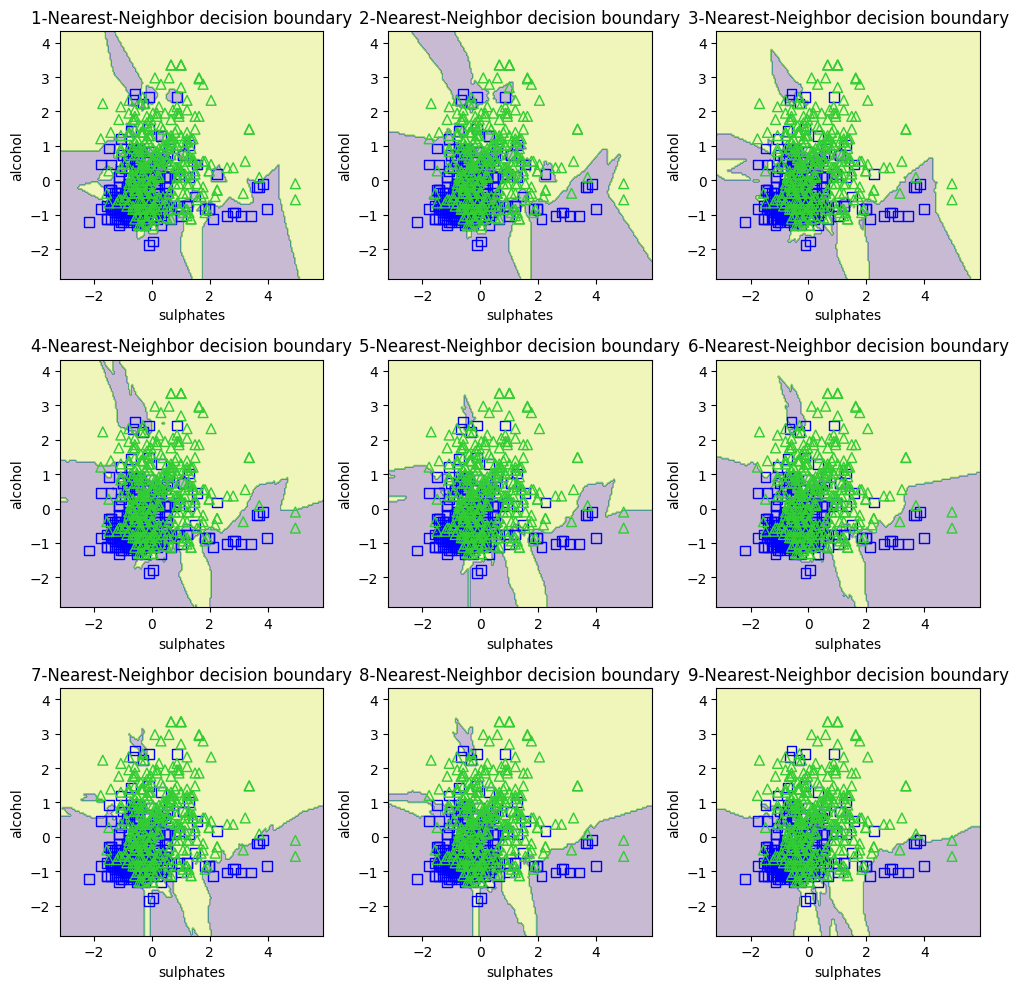

In [100]:
# Pick features
feat = ["sulphates", "alcohol"]

# Convert to NumPy so [:, 0] indexing works
Xtr = X_train[feat].values
Xte = X_test[feat].values
ytr = np.asarray(y_train)
yte = np.asarray(y_test)

# Train KNN for k=1..9
clfs = []
for k in range(1, 10):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(Xtr, ytr)
    clfs.append(knn)

# Grid for decision boundaries
fig, ax = plt.subplots(3, 3, figsize=(10, 10))
ax = ax.flatten()
h = 0.05
x_min, x_max = Xtr[:, 0].min() - 1, Xtr[:, 0].max() + 1
y_min, y_max = Xtr[:, 1].min() - 1, Xtr[:, 1].max() + 1   # fixed: Xtr, not y_train
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
X_predict = np.c_[xx.ravel(), yy.ravel()]

accuracy = []
for clf, name, a in zip(clfs, [f"{k}-Nearest-Neighbor" for k in range(1, 10)], ax):
    Z = clf.predict(X_predict).reshape(xx.shape)
    a.contourf(xx, yy, Z, alpha=0.3)
    a.set_title(f"{name} decision boundary")
    a.set_xlabel(feat[0])
    a.set_ylabel(feat[1])

    test_accuracy = np.mean(clf.predict(Xte) == yte)
    train_accuracy = np.mean(clf.predict(Xtr) == ytr)
    print(f"{name} train accuracy: {train_accuracy:.3f}  test accuracy: {test_accuracy:.3f}")
    accuracy.append(test_accuracy)

best_k = np.argmax(accuracy) + 1
print(f"Best k: {best_k}")

# Plot the training data
colors, markers = ["blue", "limegreen", "gray", "cyan"], "s^oxv<>"
for a in ax:
    for i, cls in enumerate(np.unique(ytr)):
        a.scatter(Xtr[ytr == cls, 0], Xtr[ytr == cls, 1],
                  color=colors[i], marker=markers[i], s=50, facecolors="none")

fig.tight_layout()
plt.show()

k=1 gives train accuracy 0.93 but much lower validation accuracy, i.e. overfitting. The "best k" from one split is not reliable, so k is chosen using many splits below.

The data seems to overlap quite a lot, so we want to examine whether we can classify the quality better with a kernel SVM (scikit-learn SVC) using different kernels.

#### Kernel SVM

In [101]:
import time

# 1) Subsample for the separability check (training accuracy only needs the train set)
n = min(2000, len(X_train))
Xs = X_train.iloc[:n]
ys = y_train.iloc[:n] if hasattr(y_train, "iloc") else y_train[:n]

# 2) Moderate C, an iteration cap, and a bigger kernel cache
kernels = {
    "linear":       SVC(kernel="linear", C=1000, max_iter=100_000, cache_size=1000),
    "poly (deg 2)": SVC(kernel="poly", degree=2, C=1000, max_iter=100_000, cache_size=1000),
    "poly (deg 3)": SVC(kernel="poly", degree=3, C=1000, max_iter=100_000, cache_size=1000),
    "rbf":          SVC(kernel="rbf", gamma="scale", C=1000, max_iter=100_000, cache_size=1000),
}

for name, svm in kernels.items():
    t0 = time.time()
    svm.fit(Xs, ys)
    tr = accuracy_score(ys, svm.predict(Xs))            # train accuracy
    va = accuracy_score(y_test, svm.predict(X_test))    # validation accuracy
    print(f"{name:14s} train: {tr:.3f}  validation: {va:.3f}  ({time.time() - t0:.1f}s)")

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


linear         train: 0.636  validation: 0.656  (0.5s)


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


poly (deg 2)   train: 0.751  validation: 0.688  (0.3s)
poly (deg 3)   train: 0.964  validation: 0.688  (0.3s)
rbf            train: 0.994  validation: 0.706  (0.1s)


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


With C=1000 the rbf and poly-3 kernels fit the training data almost perfectly, but validation accuracy is much lower (overfitting). The ConvergenceWarning also shows that C=1000 is too large. C and gamma are therefore tuned below.

**Hyperparameter search with many train/validation splits**
As required in the assignment, each parameter combination is evaluated on 20 different random train/validation splits of the training data, and we choose the parameters with the highest mean validation accuracy.

In [102]:
def mean_val_acc(model, X, y, n_splits=20):
    """Mean validation accuracy over many random train/validation splits."""
    accs = []
    for seed in range(n_splits):
        X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
        model.fit(X_tr, y_tr)
        accs.append(accuracy_score(y_va, model.predict(X_va)))
    return np.mean(accs)

selected = ["alcohol", "volatile acidity", "total sulfur dioxide", "sulphates"]
results = []
for fs_name, cols in [("all", list(X.columns)), ("selected", selected)]:
    Xf = X[cols]
    for C in [0.1, 1, 10, 100]:
        for gamma in [0.01, 0.03, 0.1, 0.3, 1]:
            results.append(("SVC rbf", fs_name, f"C={C}, gamma={gamma}",
                            mean_val_acc(SVC(kernel="rbf", C=C, gamma=gamma), Xf, y)))
    for k in range(1, 40, 2):
        results.append(("kNN", fs_name, f"k={k}", mean_val_acc(KNeighborsClassifier(n_neighbors=k), Xf, y)))
    for d in [2, 3, 5, 8, None]:
        results.append(("Decision tree", fs_name, f"max_depth={d}",
                        mean_val_acc(DecisionTreeClassifier(max_depth=d, random_state=42), Xf, y)))

res = pd.DataFrame(results, columns=["model", "features", "params", "mean_val_acc"])
res.sort_values("mean_val_acc", ascending=False).head(10)

,model,features,params,mean_val_acc
53,SVC rbf,selected,"C=1, gamma=0.3",0.777812
54,SVC rbf,selected,"C=1, gamma=1",0.775312
57,SVC rbf,selected,"C=10, gamma=0.1",0.774687
56,SVC rbf,selected,"C=10, gamma=0.03",0.774375
52,SVC rbf,selected,"C=1, gamma=0.1",0.774063
7,SVC rbf,all,"C=1, gamma=0.1",0.773750
61,SVC rbf,selected,"C=100, gamma=0.03",0.772500
60,SVC rbf,selected,"C=100, gamma=0.01",0.772188
48,SVC rbf,selected,"C=0.1, gamma=0.3",0.770000
8,SVC rbf,all,"C=1, gamma=0.3",0.769062


The best model is SVC with rbf kernel (C=1, gamma=0.3) on the four selected features (alcohol, volatile acidity, total sulfur dioxide, sulphates), with mean validation accuracy 0.778. It is chosen because it has the highest mean validation accuracy over the 20 splits. The top 10 results are all rbf-SVMs, and most use the selected features, so using only the features with |r| > 0.2 works slightly better than using all 11.

### Final evaluation

In [103]:
# Train the best model (highest mean validation accuracy) on all (cleaned, standardised) training data
final_cols = selected
best_model = SVC(kernel="rbf", C=1, gamma=0.3)
best_model.fit(train_sc[final_cols], y)

y_test_pred = best_model.predict(test_sc[final_cols])

### Kaggle submission

In [104]:
# Check that the IDs in the sample submission match the Id column in test
print(set(sample_sub["ID"]) == set(test["Id"]))

False


In [105]:
# The sample submission uses the row number of test.csv as ID
submission = sample_sub.copy()
submission["quality"] = y_test_pred

submission.to_csv("/content/drive/MyDrive/DAT200_CA_H26/submission.csv", index=False)
submission.head()

,ID,quality
0,0,1
1,1,1
2,2,0
3,3,1
4,4,0


### References:
* https://stackoverflow.com/questions/64161419/how-can-i-convert-the-standardscaler-transformation-back-to-dataframe
* https://scikit-learn.org/stable/modules/svm.html
* https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html